In [24]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ramped,stepped,has_ace,has_nce
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,True,False
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,True,False
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,True,False
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,True,False
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,NaN,0,NaN,NaN,NaN,NaN,False,False,True,False


In [25]:
def larger_then_prec_mz(x, tol=10.0):
    #if peaks:
    peaks = x['peaks']
    pmass = x['prec_mz']
    mz_max = max(peaks, key=lambda x: x[0])[0]
    return pmass * ( 1 + tol / 1_000_000) <= mz_max

nist_spectra_df['larger_then_pmass_peaks'] = nist_spectra_df.apply(lambda x: larger_then_prec_mz(x, 10), axis=1)

In [26]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist20_hr'])]
nist_spectra_df.shape
print(nist_spectra_df['larger_then_pmass_peaks'].sum())

258172


In [27]:
nist_spectra_df.loc[:, 'ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500 if pd.isnull(x['ace']) else x['ace'] , 0), axis=1)
nist_spectra_df.loc[:, 'nce'] = nist_spectra_df.apply(lambda x: round(x['ace'] * 500 / x['prec_mz'] if pd.isnull(x['nce']) else x['nce'] , 0), axis=1)

In [28]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = nist_spectra_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 6091

Top adduct types:

prec_type
[M+H]+                       311072
[M-H]-                       123854
[M+H-H2O]+                    84118
[M+Na]+                       38337
[2M+H]+                       28761
                              ...  
[M+H-CH6O2-C2H6O3-CO]+            1
[M+H-CH6O2-CH4O2-C4H4O2]+         1
[M+H-CH6O2-H2O]+                  1
[M-H-C4H8O4-CH4O]-                1
[M+H-C5H8O2-C5H10O2]+             1
Name: count, Length: 6091, dtype: int64


In [29]:
# Group by both prec_type and inst_type
prec_inst_counts = nist_spectra_df.groupby(['prec_type', 'inst_type']).size().reset_index(name='count')

# Create a pivot table for better visualization
prec_inst_pivot = prec_inst_counts.pivot_table(index='prec_type', columns='inst_type', values='count', fill_value=0)

# Display the top 20 adduct types by total count
total_by_prec = prec_inst_pivot.sum(axis=1).sort_values(ascending=False)
top_20_prec_types = total_by_prec.head(20).index

print("Top 20 adduct types by instrument type:")
print("="*60)
display(prec_inst_pivot.loc[top_20_prec_types])

# Show summary statistics
print(f"\nSummary:")
print(f"Total unique adduct types: {len(prec_inst_pivot)}")
print(f"Total unique instrument types: {len(prec_inst_pivot.columns)}")
print(f"\nInstrument types available:")
for inst_type in prec_inst_pivot.columns:
    total_spectra = prec_inst_pivot[inst_type].sum()
    print(f"  {inst_type}: {total_spectra:,} spectra")

Top 20 adduct types by instrument type:


inst_type,FT,QTOF
prec_type,,
[M+H]+,286499.0,24573.0
[M-H]-,121450.0,2404.0
[M+H-H2O]+,79520.0,4598.0
[M+Na]+,37065.0,1272.0
[2M+H]+,25387.0,3374.0
[M+H+2i]+,26779.0,0.0
[2M-H]-,24153.0,925.0
[M+H-2H2O]+,15810.0,0.0
[M+H-NH3]+,13145.0,731.0



Summary:
Total unique adduct types: 6091
Total unique instrument types: 2

Instrument types available:
  FT: 964,295.0 spectra
  QTOF: 41,602.0 spectra


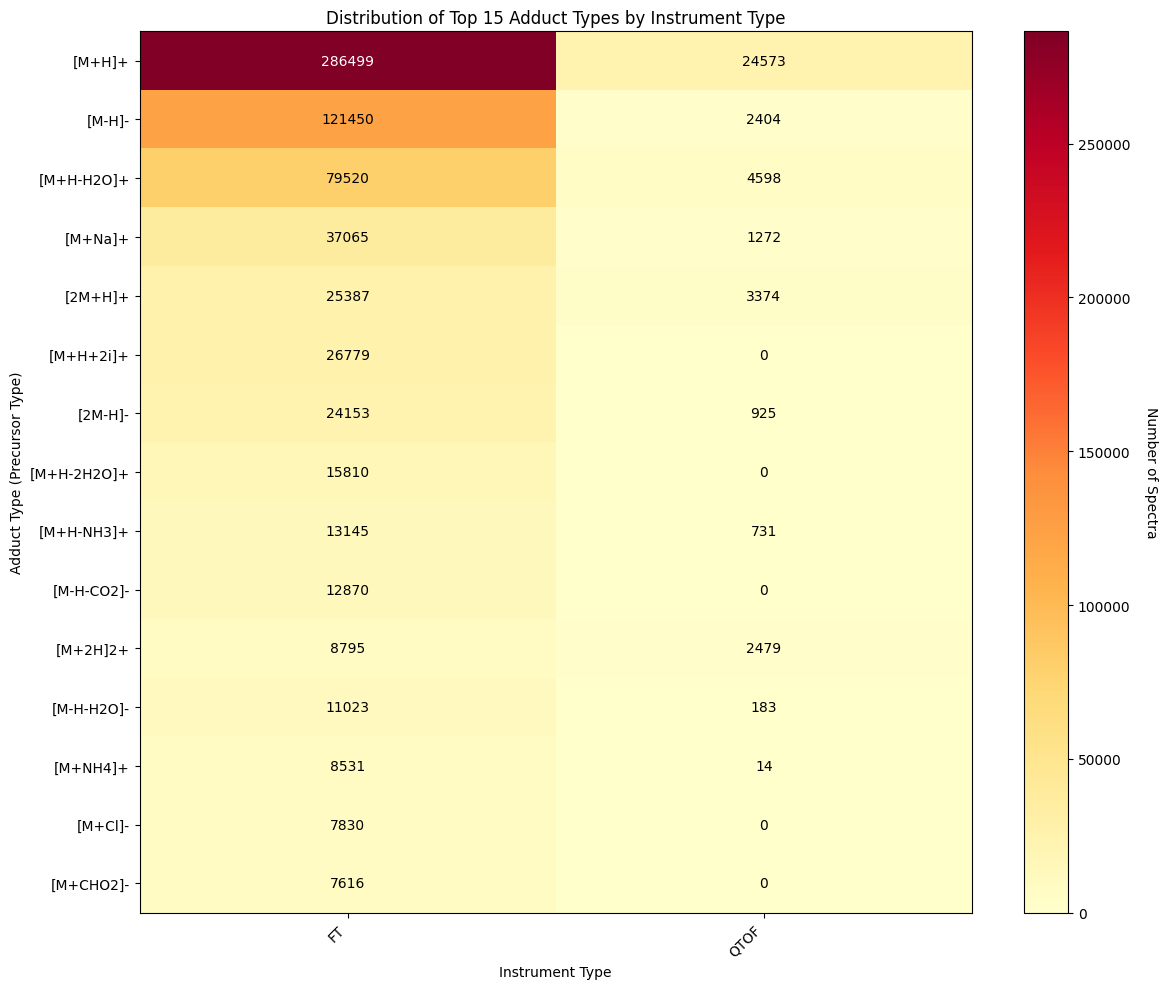


Percentage distribution by instrument type for top 10 adduct types:


inst_type,FT,QTOF
prec_type,,
[M+H]+,92.1,7.9
[M-H]-,98.1,1.9
[M+H-H2O]+,94.5,5.5
[M+Na]+,96.7,3.3
[2M+H]+,88.3,11.7
[M+H+2i]+,100.0,0.0
[2M-H]-,96.3,3.7
[M+H-2H2O]+,100.0,0.0
[M+H-NH3]+,94.7,5.3


In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Create a heatmap for the top 15 adduct types using matplotlib
top_15_prec_types = total_by_prec.head(15).index
heatmap_data = prec_inst_pivot.loc[top_15_prec_types]

fig, ax = plt.subplots(figsize=(12, 10))

# Create the heatmap using imshow
im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto')

# Set ticks and labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha='right')
ax.set_yticklabels(heatmap_data.index)

# Add text annotations
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        text = ax.text(j, i, int(heatmap_data.iloc[i, j]),
                      ha="center", va="center", color="black" if heatmap_data.iloc[i, j] < heatmap_data.values.max()/2 else "white")

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Number of Spectra', rotation=270, labelpad=20)

# Set labels and title
ax.set_title('Distribution of Top 15 Adduct Types by Instrument Type')
ax.set_xlabel('Instrument Type')
ax.set_ylabel('Adduct Type (Precursor Type)')

plt.tight_layout()
plt.show()

# Show the percentage distribution for each adduct type
print("\nPercentage distribution by instrument type for top 10 adduct types:")
print("="*70)
top_10_prec_types = total_by_prec.head(10).index
percentage_data = prec_inst_pivot.loc[top_10_prec_types].div(prec_inst_pivot.loc[top_10_prec_types].sum(axis=1), axis=0) * 100
display(percentage_data.round(1))

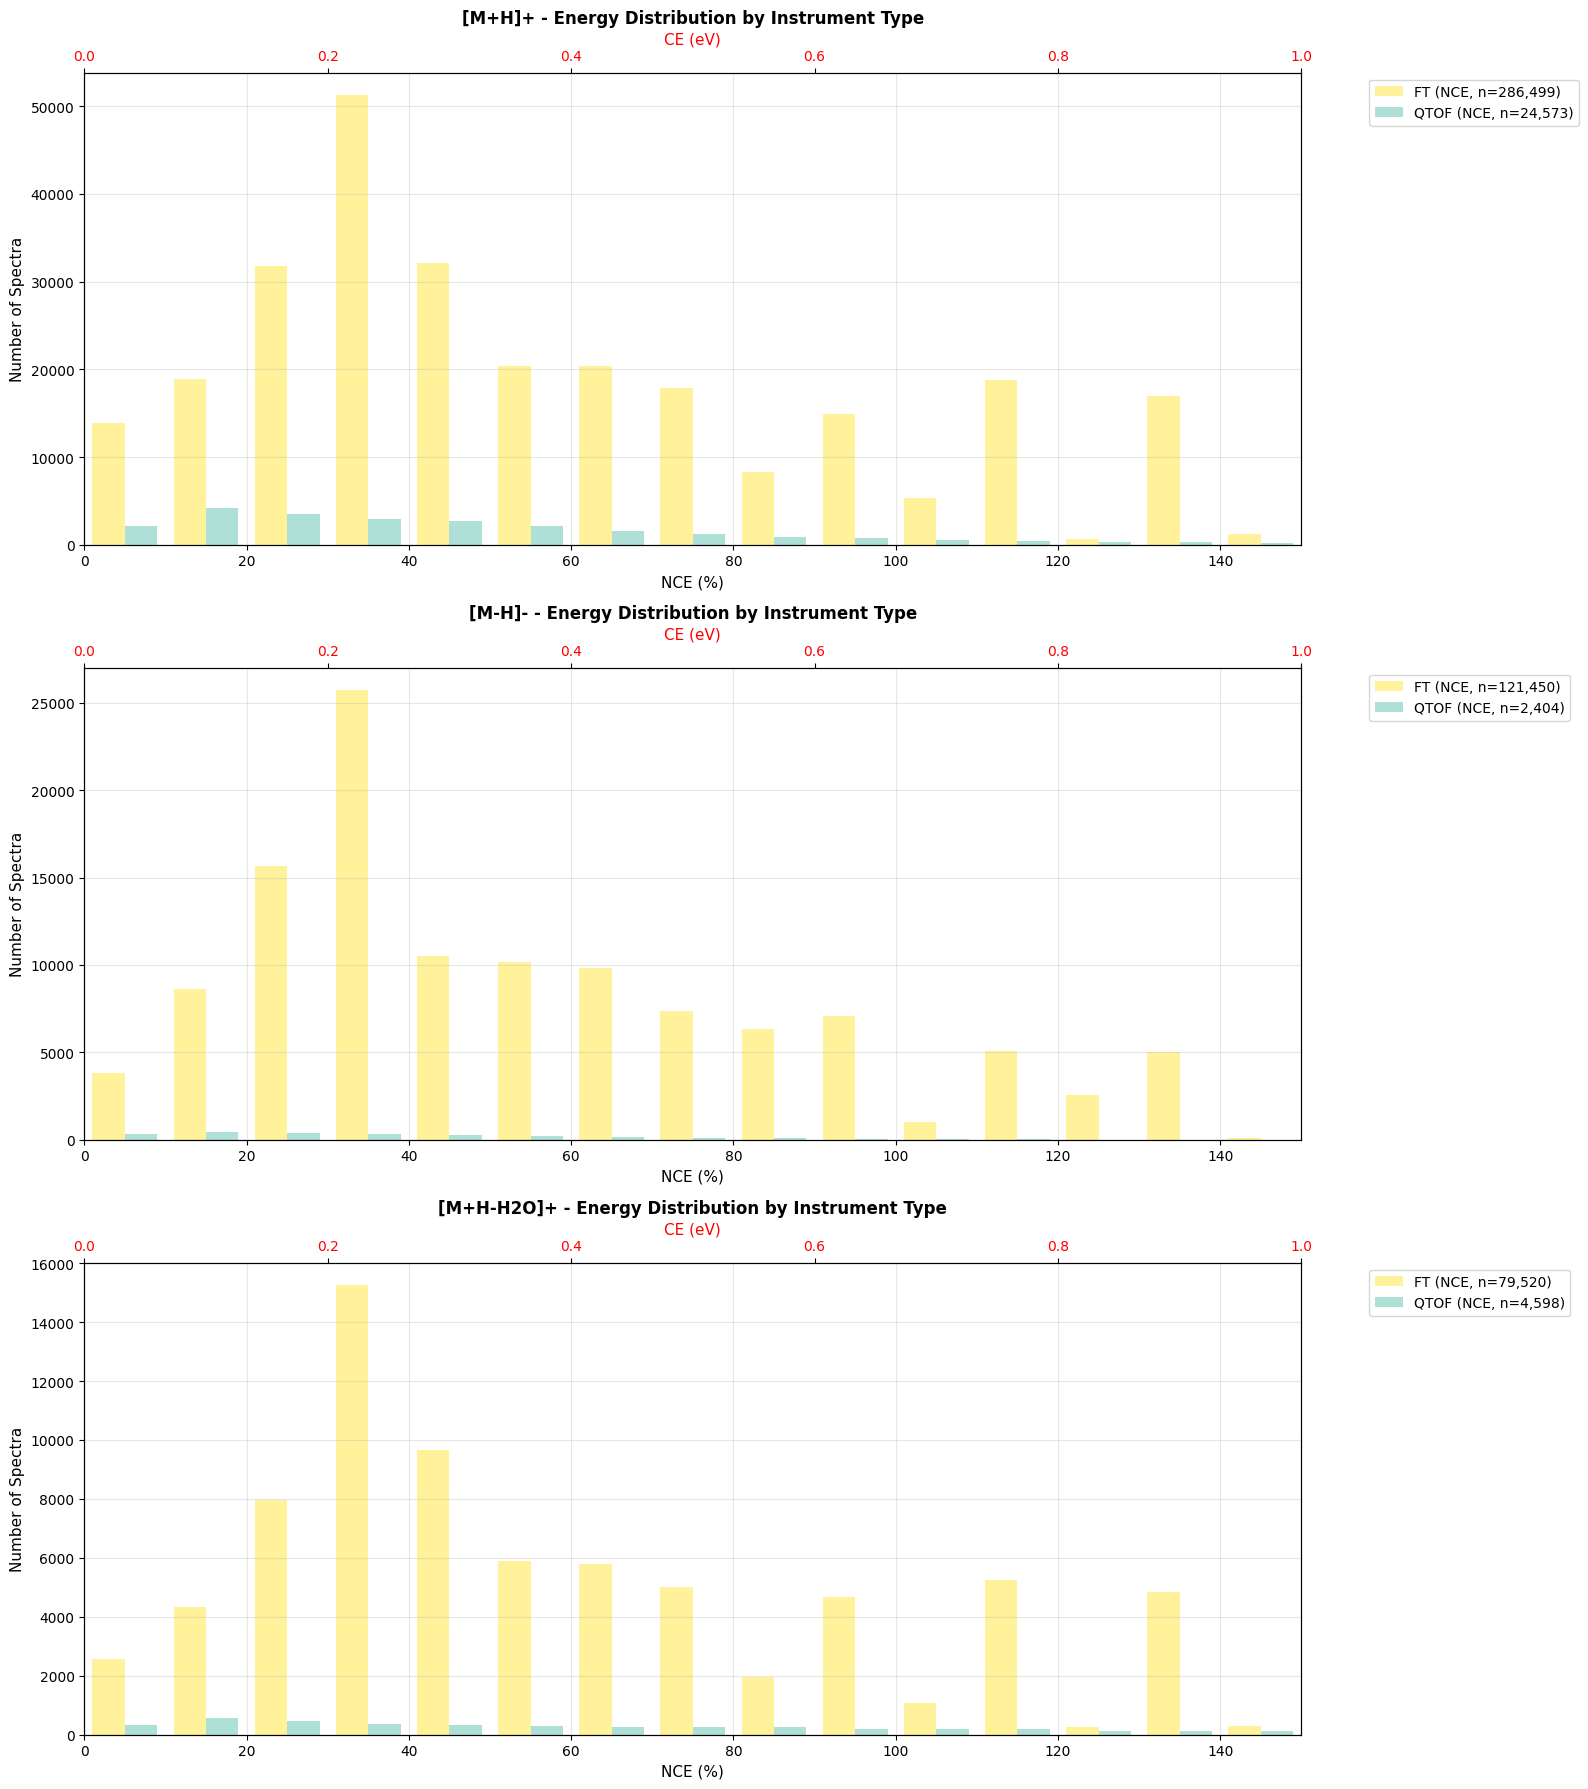

Summary statistics by adduct type and instrument type:

[M+H]+:


,Instrument,Energy Type,Count,Mean,Std,Min,Max
0,QTOF,NCE (%),24573,47.3,38.6,1.0,375.0
1,FT,NCE (%),286499,59.9,41.6,2.0,195.0



[M-H]-:


,Instrument,Energy Type,Count,Mean,Std,Min,Max
0,QTOF,NCE (%),2404,36.8,27.6,1.0,170.0
1,FT,NCE (%),121450,55.6,36.4,2.0,160.0



[M+H-H2O]+:


,Instrument,Energy Type,Count,Mean,Std,Min,Max
0,QTOF,NCE (%),4598,71.3,56.6,1.0,381.0
1,FT,NCE (%),79520,62.3,42.0,2.0,195.0


In [31]:
import numpy as np

# Create a copy of the dataframe with CE/NCE values based on instrument type
plot_df = nist_spectra_df.copy()

# For QToF instruments, we'll use a CE approximation (ACE values)
# For other instruments, we'll use NCE
plot_df['energy_value'] = plot_df['nce']  # Default to NCE
plot_df['energy_type'] = 'NCE (%)'       # Default energy type

# For QToF instruments, use CE (approximated by ACE values)
qtof_mask = plot_df['inst_type'] == 'QToF'
plot_df.loc[qtof_mask, 'energy_value'] = plot_df.loc[qtof_mask, 'ace']
plot_df.loc[qtof_mask, 'energy_type'] = 'CE (eV)'

# Group by prec_type, inst_type, and energy_value to get counts
prec_inst_energy_counts = plot_df.groupby(['prec_type', 'inst_type', 'energy_value']).size().reset_index(name='count')

# Get the top 3 adduct types by total count
adduct_totals = plot_df['prec_type'].value_counts()
top_3_adducts = adduct_totals.head(3).index

# Get available instrument types
inst_types = plot_df['inst_type'].unique()
n_inst_types = len(inst_types)

# Create a figure with subplots for each adduct type
fig, axes = plt.subplots(len(top_3_adducts), 1, figsize=(16, 6 * len(top_3_adducts)))
if len(top_3_adducts) == 1:
    axes = [axes]

# Colors for different instrument types
colors = plt.cm.Set3(np.linspace(0, 1, n_inst_types))

for adduct_idx, adduct in enumerate(top_3_adducts):
    ax = axes[adduct_idx]
    ax2 = ax.twiny()  # Create second x-axis for CE values
    
    # Filter data for this adduct
    adduct_data = prec_inst_energy_counts[prec_inst_energy_counts['prec_type'] == adduct]
    
    # Separate QToF and non-QToF data
    qtof_data = adduct_data[adduct_data['inst_type'] == 'QToF']
    non_qtof_data = adduct_data[adduct_data['inst_type'] != 'QToF']
    
    # Plot NCE data (non-QToF instruments) on primary axis
    if len(non_qtof_data) > 0:
        # Define NCE bins
        nce_bin_size = 10
        nce_bins = np.arange(0, 200, nce_bin_size)
        nce_bin_centers = nce_bins[:-1] + nce_bin_size/2
        
        non_qtof_inst_types = non_qtof_data['inst_type'].unique()
        n_non_qtof = len(non_qtof_inst_types)
        
        for inst_idx, inst_type in enumerate(non_qtof_inst_types):
            inst_data = non_qtof_data[non_qtof_data['inst_type'] == inst_type]
            
            # Create binned data for NCE
            binned_counts = np.zeros(len(nce_bins)-1)
            for _, row in inst_data.iterrows():
                energy_val = row['energy_value']
                count = row['count']
                bin_idx = np.digitize(energy_val, nce_bins) - 1
                if 0 <= bin_idx < len(binned_counts):
                    binned_counts[bin_idx] += count
            
            # Plot as bar chart
            width = nce_bin_size * 0.8 / n_non_qtof if n_non_qtof > 1 else nce_bin_size * 0.8
            offset = (inst_idx - n_non_qtof/2 + 0.5) * width if n_non_qtof > 1 else 0
            
            color_idx = list(inst_types).index(inst_type)
            ax.bar(nce_bin_centers + offset, binned_counts, width=width, 
                   label=f'{inst_type} (NCE, n={inst_data["count"].sum():,})', 
                   color=colors[color_idx], alpha=0.7)
    
    # Plot CE data (QToF) on secondary axis
    if len(qtof_data) > 0:
        # Define CE bins
        ce_bin_size = 5
        ce_bins = np.arange(0, 100, ce_bin_size)
        ce_bin_centers = ce_bins[:-1] + ce_bin_size/2
        
        # Create binned data for CE
        binned_counts = np.zeros(len(ce_bins)-1)
        for _, row in qtof_data.iterrows():
            energy_val = row['energy_value']
            count = row['count']
            bin_idx = np.digitize(energy_val, ce_bins) - 1
            if 0 <= bin_idx < len(binned_counts):
                binned_counts[bin_idx] += count
        
        # Plot as bar chart on secondary axis
        qtof_color_idx = list(inst_types).index('QToF')
        ax2.bar(ce_bin_centers, binned_counts, width=ce_bin_size * 0.8, 
               label=f'QToF (CE, n={qtof_data["count"].sum():,})', 
               color=colors[qtof_color_idx], alpha=0.7, edgecolor='black', linewidth=1)
    
    # Set labels and title
    ax.set_title(f'{adduct} - Energy Distribution by Instrument Type', fontsize=12, fontweight='bold')
    ax.set_xlabel('NCE (%)', fontsize=11)
    ax.set_ylabel('Number of Spectra', fontsize=11)
    ax2.set_xlabel('CE (eV)', fontsize=11, color='red')
    ax2.tick_params(axis='x', labelcolor='red')
    
    # Combine legends from both axes
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    ax.grid(True, alpha=0.3)
    
    # Set reasonable axis limits
    ax.set_xlim(0, 150)
    if len(qtof_data) > 0:
        ax2.set_xlim(0, 80)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary statistics by adduct type and instrument type:")
print("="*70)
for adduct in top_3_adducts:
    print(f"\n{adduct}:")
    adduct_subset = plot_df[plot_df['prec_type'] == adduct]
    
    # Create summary for each instrument type
    summary_data = []
    for inst_type in inst_types:
        inst_data = adduct_subset[adduct_subset['inst_type'] == inst_type]
        if len(inst_data) > 0:
            energy_col = 'energy_value'
            energy_type = inst_data['energy_type'].iloc[0]
            
            summary_data.append({
                'Instrument': inst_type,
                'Energy Type': energy_type,
                'Count': len(inst_data),
                'Mean': inst_data[energy_col].mean().round(1),
                'Std': inst_data[energy_col].std().round(1),
                'Min': inst_data[energy_col].min(),
                'Max': inst_data[energy_col].max()
            })
    
    summary_df = pd.DataFrame(summary_data)
    display(summary_df)

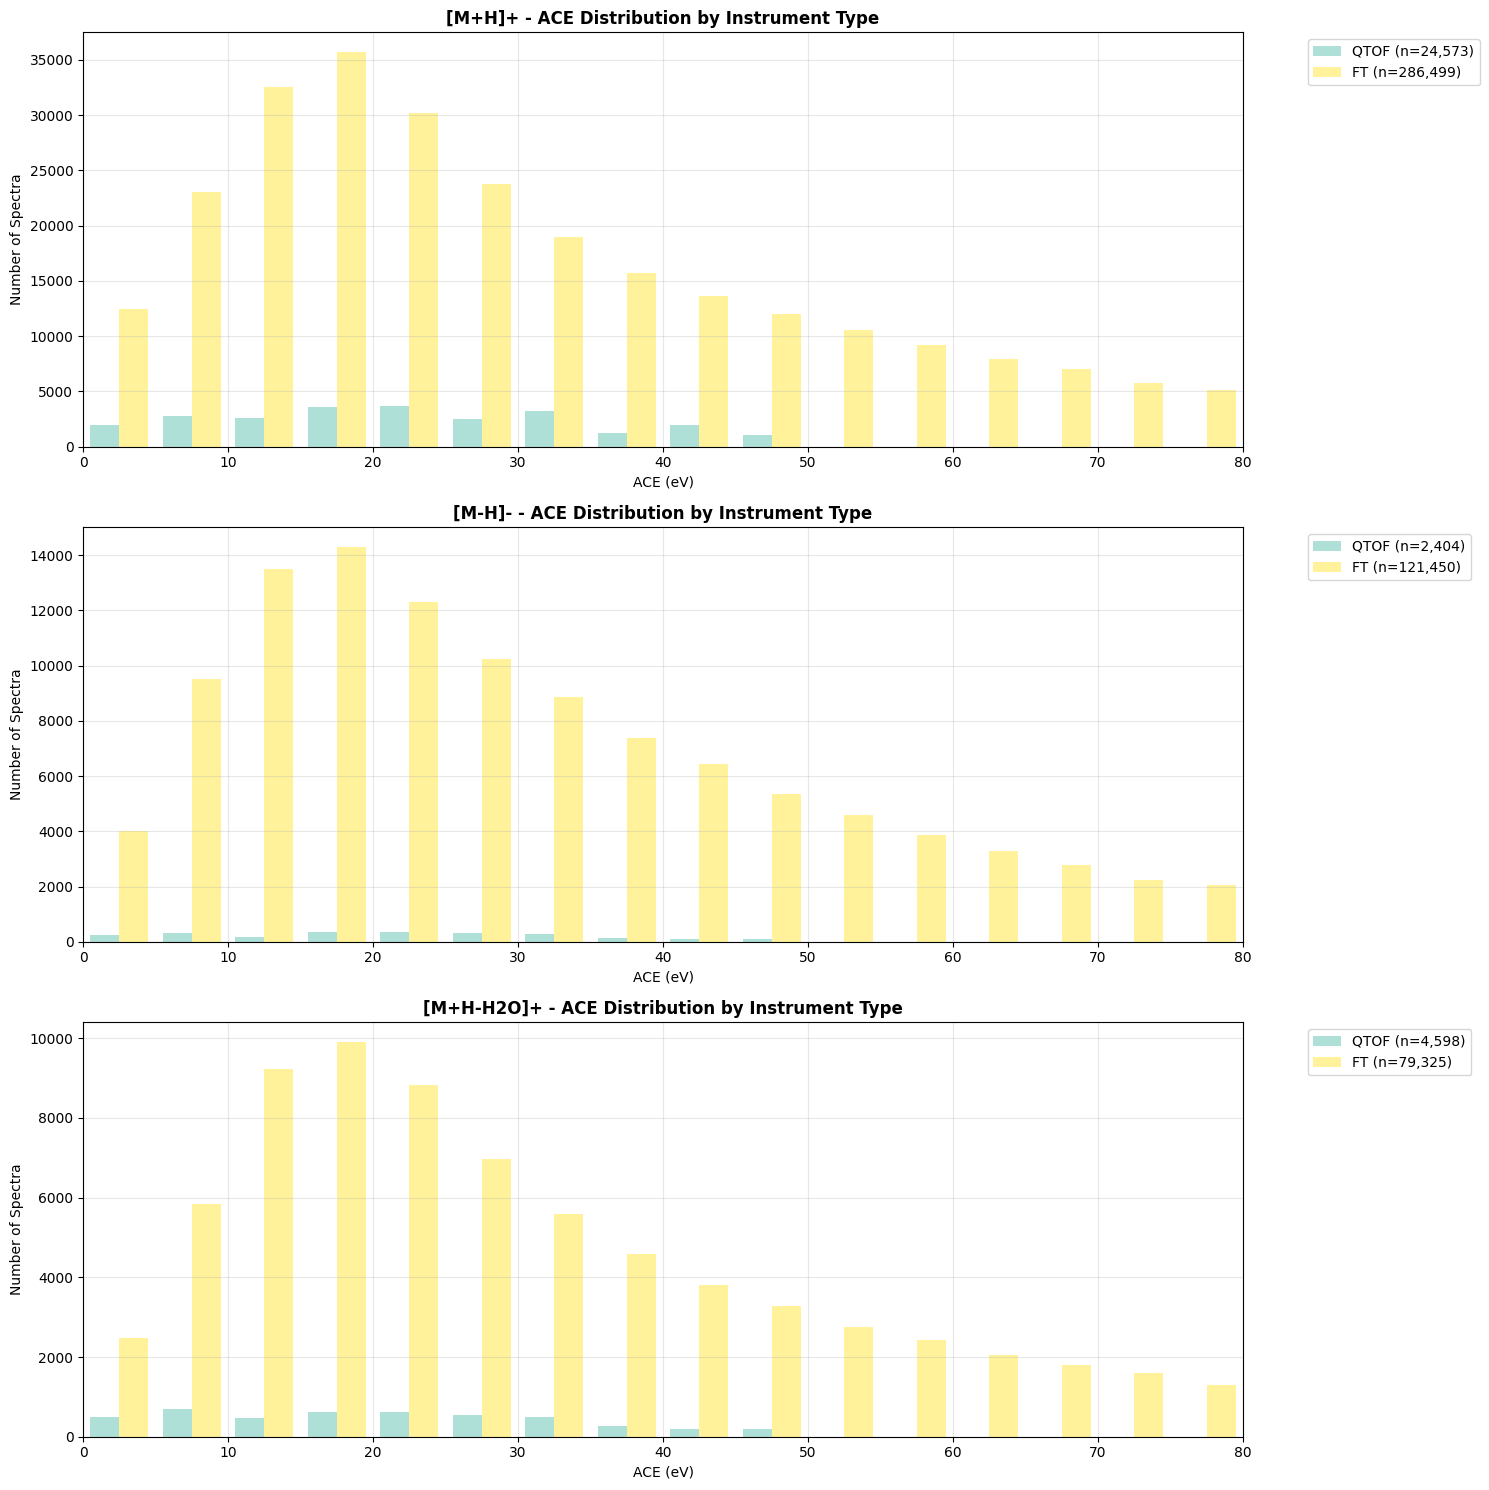

Summary statistics by adduct type and instrument type:

[M+H]+:


,Count,Mean ACE,Std ACE,Min ACE,Max ACE
inst_type,,,,,
FT,286499,35.0,28.4,0.0,329.0
QTOF,24573,21.1,12.1,1.0,60.0



[M-H]-:


,Count,Mean ACE,Std ACE,Min ACE,Max ACE
inst_type,,,,,
FT,121450,36.6,30.1,0.0,322.0
QTOF,2404,20.3,12.1,1.0,60.0



[M+H-H2O]+:


,Count,Mean ACE,Std ACE,Min ACE,Max ACE
inst_type,,,,,
FT,79325,35.8,28.8,0.0,294.0
QTOF,4598,19.6,12.0,2.0,60.0


In [32]:
import numpy as np

# Group by prec_type, inst_type, and ace to get counts
prec_inst_ace_counts = nist_spectra_df.groupby(['prec_type', 'inst_type', 'ace']).size().reset_index(name='count')

# Get the top 3 adduct types by total count
adduct_totals = nist_spectra_df['prec_type'].value_counts()
top_3_adducts = adduct_totals.head(3).index

# Get available instrument types
inst_types = nist_spectra_df['inst_type'].unique()
n_inst_types = len(inst_types)

# Create a figure with subplots for each adduct type
fig, axes = plt.subplots(len(top_3_adducts), 1, figsize=(15, 5 * len(top_3_adducts)))
if len(top_3_adducts) == 1:
    axes = [axes]

# Define ACE bins
ace_bin_size = 5
bins = np.arange(0, 100, ace_bin_size)
bin_centers = bins[:-1] + ace_bin_size/2

# Colors for different instrument types
colors = plt.cm.Set3(np.linspace(0, 1, n_inst_types))

for adduct_idx, adduct in enumerate(top_3_adducts):
    ax = axes[adduct_idx]
    
    # Filter data for this adduct
    adduct_data = prec_inst_ace_counts[prec_inst_ace_counts['prec_type'] == adduct]
    
    # Plot histogram for each instrument type
    for inst_idx, inst_type in enumerate(inst_types):
        inst_data = adduct_data[adduct_data['inst_type'] == inst_type]
        
        if len(inst_data) > 0:
            # Create binned data
            binned_counts = np.zeros(len(bins)-1)
            for _, row in inst_data.iterrows():
                ace_val = row['ace']
                count = row['count']
                bin_idx = np.digitize(ace_val, bins) - 1
                if 0 <= bin_idx < len(binned_counts):
                    binned_counts[bin_idx] += count
            
            # Plot as bar chart with offset for each instrument type
            width = ace_bin_size * 0.8 / n_inst_types
            offset = (inst_idx - n_inst_types/2 + 0.5) * width
            
            ax.bar(bin_centers + offset, binned_counts, width=width, 
                   label=f'{inst_type} (n={inst_data["count"].sum():,})', 
                   color=colors[inst_idx], alpha=0.7)
    
    # Set labels and title
    ax.set_title(f'{adduct} - ACE Distribution by Instrument Type', fontsize=12, fontweight='bold')
    ax.set_xlabel('ACE (eV)')
    ax.set_ylabel('Number of Spectra')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    
    # Set reasonable x-axis limits
    ax.set_xlim(0, 80)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary statistics by adduct type and instrument type:")
print("="*70)
for adduct in top_3_adducts:
    print(f"\n{adduct}:")
    adduct_summary = nist_spectra_df[nist_spectra_df['prec_type'] == adduct].groupby('inst_type').agg({
        'ace': ['count', 'mean', 'std', 'min', 'max']
    }).round(1)
    adduct_summary.columns = ['Count', 'Mean ACE', 'Std ACE', 'Min ACE', 'Max ACE']
    display(adduct_summary)

In [33]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20/mol_df.pkl')
nist_mol_df.drop(['mol'], axis=1, inplace=True)
nist_mol_df.head()

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [34]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')
nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0


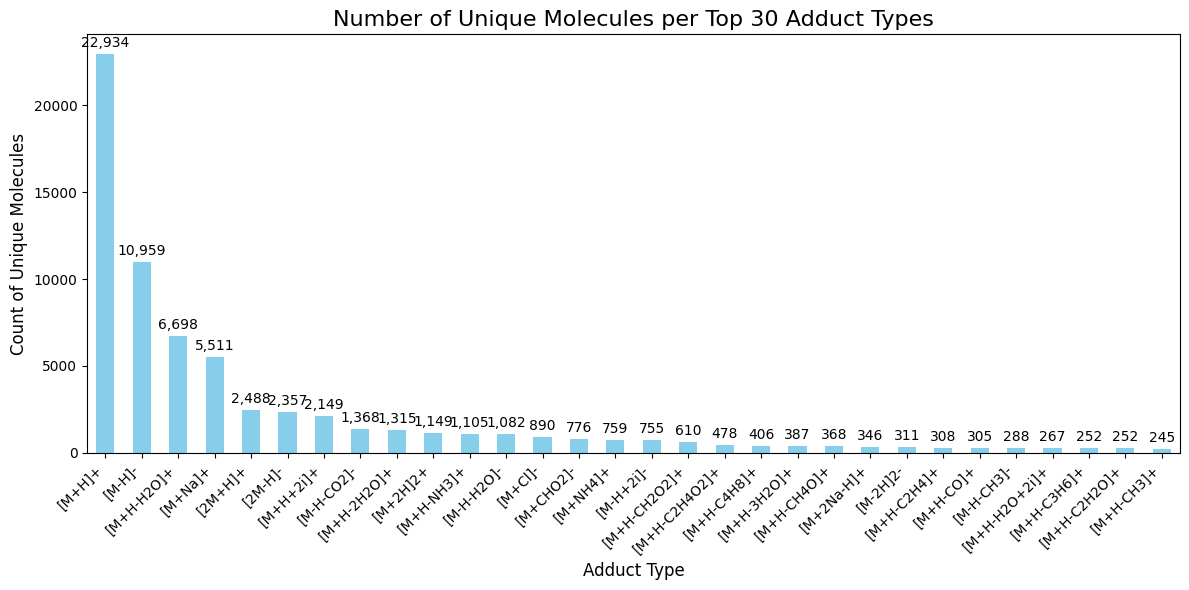

Number of unique molecules per adduct type:
prec_type
[M+H]+           22934
[M-H]-           10959
[M+H-H2O]+        6698
[M+Na]+           5511
[2M+H]+           2488
[2M-H]-           2357
[M+H+2i]+         2149
[M-H-CO2]-        1368
[M+H-2H2O]+       1315
[M+2H]2+          1149
[M+H-NH3]+        1105
[M-H-H2O]-        1082
[M+Cl]-            890
[M+CHO2]-          776
[M+NH4]+           759
[M-H+2i]-          755
[M+H-CH2O2]+       610
[M+H-C2H4O2]+      478
[M+H-C4H8]+        406
[M+H-3H2O]+        387
[M+H-CH4O]+        368
[M+2Na-H]+         346
[M-2H]2-           311
[M+H-C2H4]+        308
[M+H-CO]+          305
[M-H-CH3]-         288
[M+H-H2O+2i]+      267
[M+H-C3H6]+        252
[M+H-C2H2O]+       252
[M+H-CH3]+         245
Name: mol_id, dtype: int64


In [35]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(30)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 30 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)

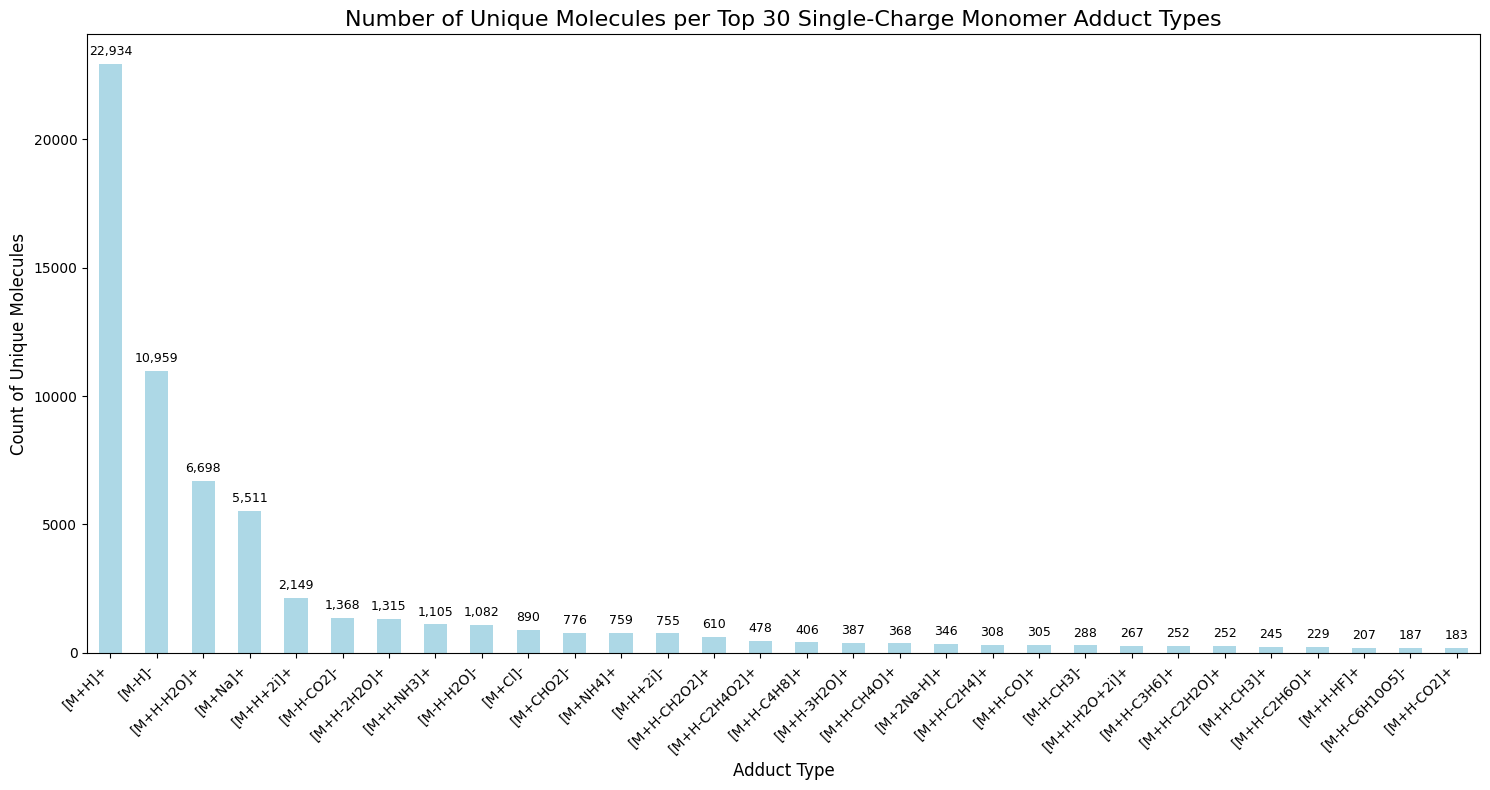

Number of unique molecules per single-charge monomer adduct type:
prec_type
[M+H]+            22934
[M-H]-            10959
[M+H-H2O]+         6698
[M+Na]+            5511
[M+H+2i]+          2149
[M-H-CO2]-         1368
[M+H-2H2O]+        1315
[M+H-NH3]+         1105
[M-H-H2O]-         1082
[M+Cl]-             890
[M+CHO2]-           776
[M+NH4]+            759
[M-H+2i]-           755
[M+H-CH2O2]+        610
[M+H-C2H4O2]+       478
[M+H-C4H8]+         406
[M+H-3H2O]+         387
[M+H-CH4O]+         368
[M+2Na-H]+          346
[M+H-C2H4]+         308
[M+H-CO]+           305
[M-H-CH3]-          288
[M+H-H2O+2i]+       267
[M+H-C3H6]+         252
[M+H-C2H2O]+        252
[M+H-CH3]+          245
[M+H-C2H6O]+        229
[M+H-HF]+           207
[M-H-C6H10O5]-      187
[M+H-CO2]+          183
Name: mol_id, dtype: int64


In [36]:
# Filter out dimer adducts (those containing '2M') and multi-charge adducts
monomer_df = nist_df[
    (~nist_df['prec_type'].str.contains('2M')) & 
    (~nist_df['prec_type'].str.contains(']2+')) & 
    (~nist_df['prec_type'].str.contains(']2-')) & 
    (~nist_df['prec_type'].str.contains(']3+')) & 
    (~nist_df['prec_type'].str.contains(']3-'))
]

# Calculate the number of unique molecules per each adduct type (excluding dimers and multi-charge)
unique_mols_per_monomer_adduct = monomer_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 30 adduct types by number of unique molecules
top_30_monomer_adducts = unique_mols_per_monomer_adduct.head(30)

# Create a bar plot
plt.figure(figsize=(15, 8))
top_30_monomer_adducts.plot(kind='bar', color='lightblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 30 Single-Charge Monomer Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_30_monomer_adducts):
    plt.text(i, v + 0.01*max(top_30_monomer_adducts), f"{v:,}", 
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per single-charge monomer adduct type:")
print(top_30_monomer_adducts)

In [37]:
frag_dp = '../../data/frag/nist20_ma_mi_d3_h4_isoFalse'
spec_frag_stats_df = pd.read_pickle(f'{frag_dp}/spec_stats_df.pkl')
spec_frag_stats_df = spec_frag_stats_df.merge(nist_df[['spec_id', 'prec_type','ace','nce','peaks']], on='spec_id', how='left')
spec_frag_stats_df.dropna(subset=['ace'], inplace=True)
spec_frag_stats_df.dropna(subset=['nce'], inplace=True)
spec_frag_stats_df.head()

,spec_id,mol_id,recall_0.01_h1,wrecall_0.01_h1,prec_0.01_h1,ppt_peak_0.01_h1,ppt_formula_0.01_h1,prec_recall_0.01_h1,prec_spec_recall_0.01_h1,recall_0.01_h2,...,depth,formula_redundancy,dag_num_edges,dag_num_nodes,dag_sparsity,dag_num_nodes_nb,prec_type,ace,nce,peaks
0,7,10998,0.200000,0.816530,0.000482,1.0,1.0,1.0,1.0,0.600000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,23.0,8.0,"[(599.5, 41.06), (873.47, 47.75), (1470.95, 86..."
1,8,10998,0.200000,0.757691,0.000482,1.0,1.0,1.0,1.0,0.600000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,30.0,10.0,"[(599.49, 52.95), (601.51, 54.15), (873.46, 13..."
2,9,10998,0.200000,0.691273,0.000482,1.0,1.0,1.0,1.0,0.400000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,35.0,12.0,"[(274.97, 74.23), (599.5, 79.22), (601.52, 50...."
3,15,10998,0.142857,0.028636,0.000482,1.0,1.0,1.0,0.0,0.285714,...,3,80.064123,597904,71201,0.000236,-1,[M-H]-,20.0,7.0,"[(29.69, 24.38), (279.24, 44.56), (415.23, 34...."
4,16,10998,0.333333,0.048806,0.000964,1.0,1.0,1.0,0.0,0.500000,...,3,80.064123,597904,71201,0.000236,-1,[M-H]-,25.0,9.0,"[(153.0, 26.67), (279.24, 45.45), (415.23, 31...."


/tmp/ipykernel_3775310/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
/tmp/ipykernel_3775310/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
/tmp/ipykernel_3775310/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warnin

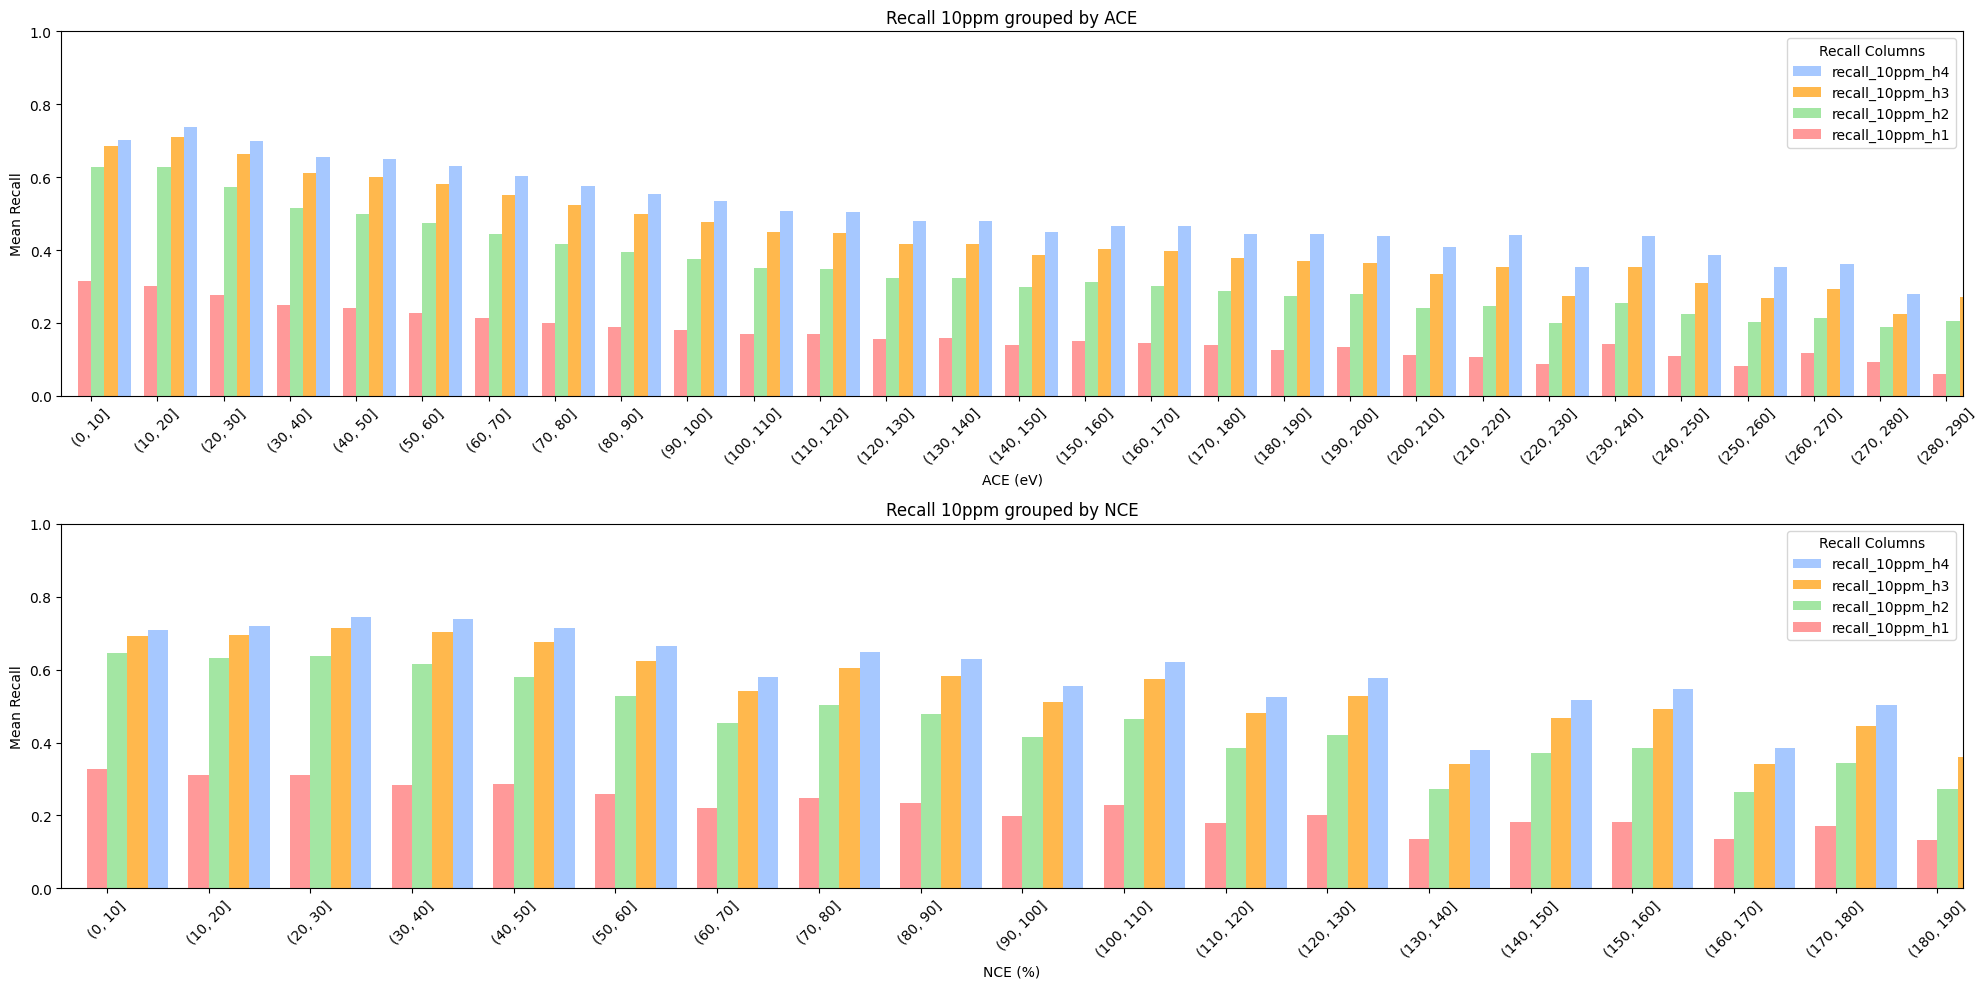

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']
recall_columns.reverse()

# Define ACE and NCE bins
ace_bin_size = 10
nce_bin_size = 10
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
axes = axes.flatten()

# New color choices (You can use color names, hex values, or RGB tuples)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot histograms for each recall column grouped by ACE
ax = axes[0]
width = 0.2  # Bar width for separation
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot histograms for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['nce'], nce_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

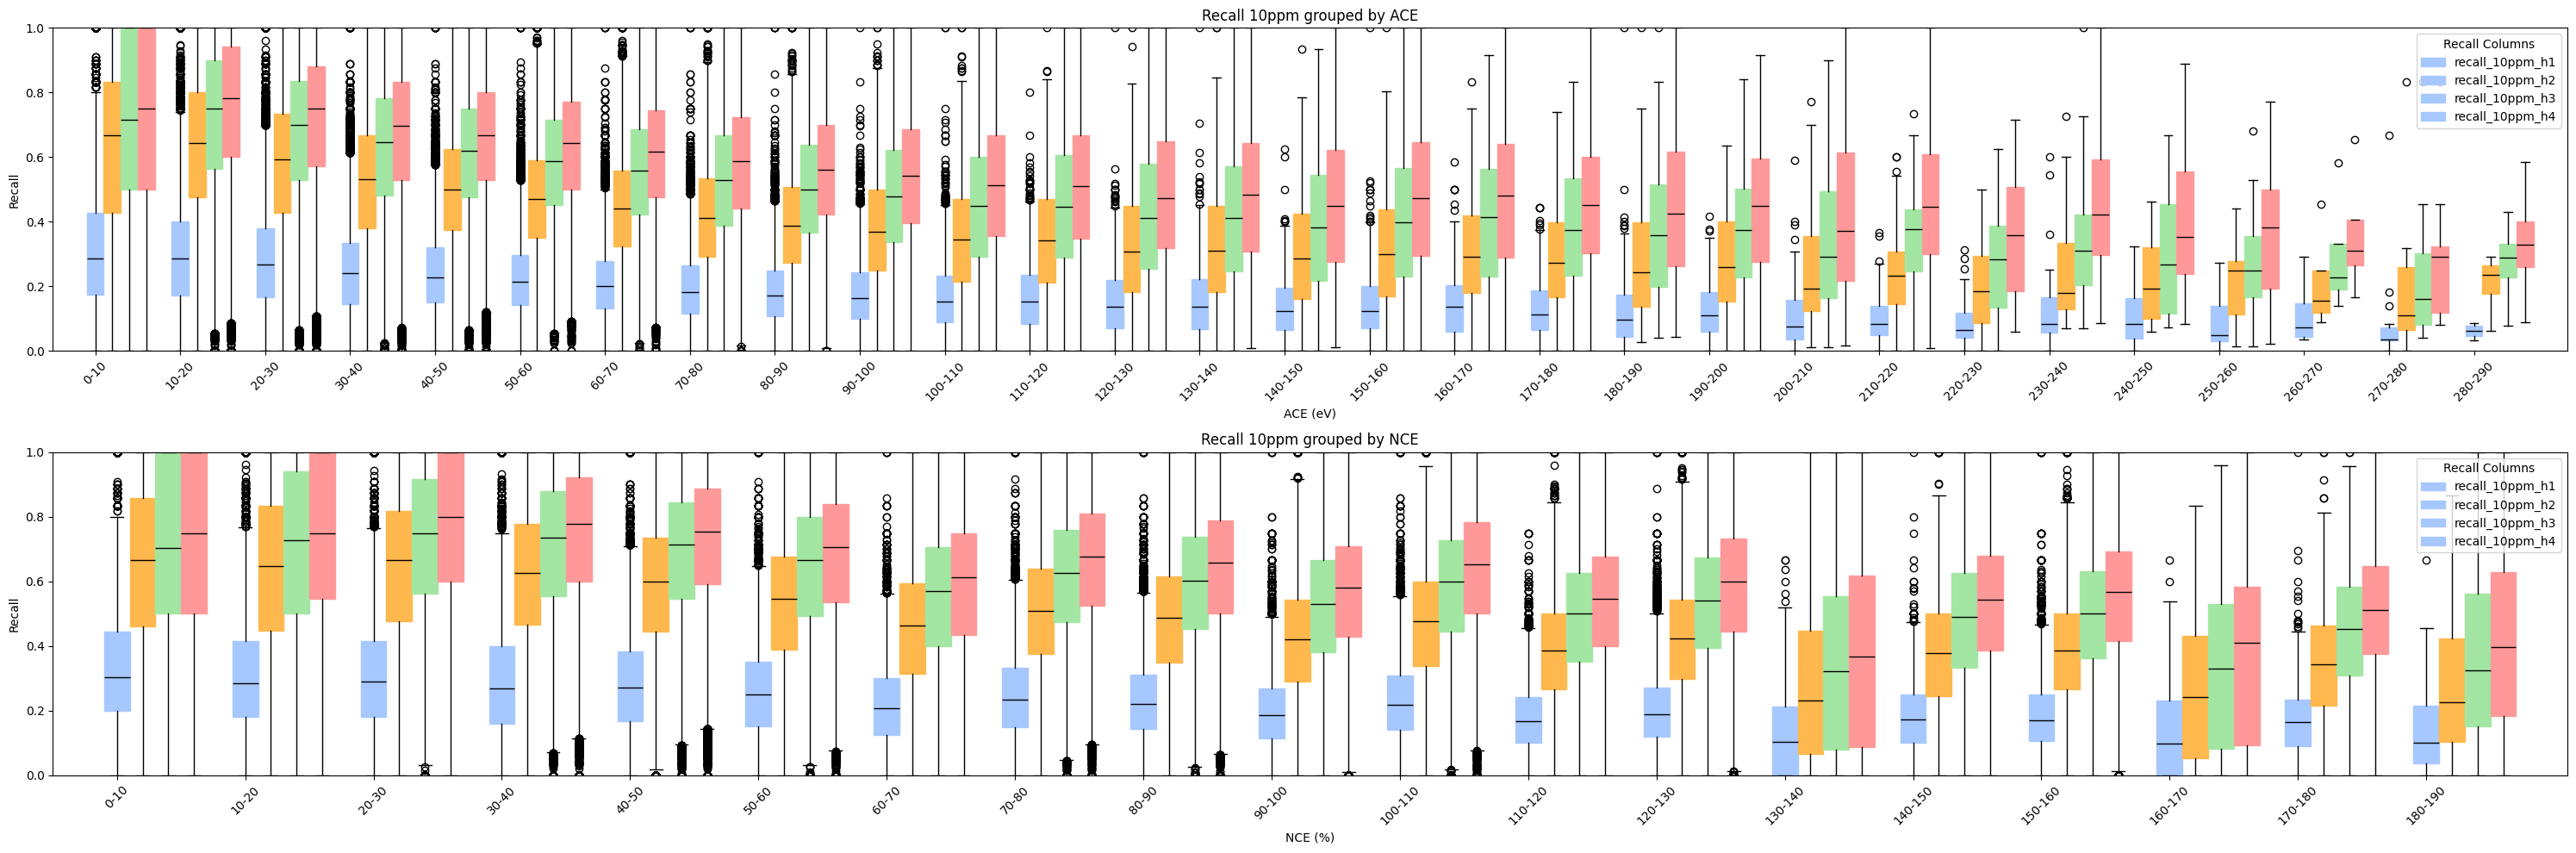

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']

# Define ACE and NCE bins
ace_bin_size = 10
nce_bin_size = 10
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a wider figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(30, 10))  # Increased the width
axes = axes.flatten()

# Lighter color choices (lighter shades of blue, orange, green, and red)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot box plots for each recall column grouped by ACE
ax = axes[0]
for i, col in enumerate(recall_columns):
    # Group by ACE bins and extract the corresponding values for boxplot
    ace_labels = pd.cut(selected_df['ace'], ace_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[ace_labels == interval][col] for interval in ace_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(ace_bins) - 1))
ax.set_xticklabels([f'{int(ace_bins[i])}-{int(ace_bins[i + 1])}' for i in range(len(ace_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot box plots for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    # Group by NCE bins and extract the corresponding values for boxplot
    nce_labels = pd.cut(selected_df['nce'], nce_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[nce_labels == interval][col] for interval in nce_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(nce_bins) - 1))
ax.set_xticklabels([f'{int(nce_bins[i])}-{int(nce_bins[i + 1])}' for i in range(len(nce_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

In [40]:
spec_frag_stats_df[(spec_frag_stats_df['ace'] <= 1.0) & (spec_frag_stats_df['recall_0.01_h4'] <= 1.0)]

,spec_id,mol_id,recall_0.01_h1,wrecall_0.01_h1,prec_0.01_h1,ppt_peak_0.01_h1,ppt_formula_0.01_h1,prec_recall_0.01_h1,prec_spec_recall_0.01_h1,recall_0.01_h2,...,depth,formula_redundancy,dag_num_edges,dag_num_nodes,dag_sparsity,dag_num_nodes_nb,prec_type,ace,nce,peaks
1051,180080,30902,0.500000,0.926355,0.040000,1.0,1.0,1.0,1.0,1.000000,...,3,2.577465,224,61,0.122404,-1,[M-H]-,1.0,5.0,"[(67.019, 79.42), (111.0087, 999.0)]"
1084,180192,8630,0.333333,0.806126,0.015152,1.0,1.0,1.0,1.0,1.000000,...,3,4.323887,662,158,0.053374,-1,[M-H]-,0.0,2.0,"[(117.0707, 20.38), (119.0864, 219.88), (163.0..."
1085,180193,8630,0.333333,0.697445,0.015152,1.0,1.0,1.0,1.0,1.000000,...,3,4.323887,662,158,0.053374,-1,[M-H]-,1.0,4.0,"[(117.0708, 69.03), (119.0864, 364.34), (163.0..."
1380,181957,1842,0.333333,0.656416,0.046512,1.0,1.0,1.0,1.0,0.666667,...,3,3.459016,584,102,0.113376,-1,[M+H]+,0.0,2.0,"[(99.044, 26.67), (113.0597, 96.8), (141.0548,..."
1381,181958,1842,0.400000,0.578453,0.046512,1.0,1.0,1.0,1.0,0.800000,...,3,3.459016,584,102,0.113376,-1,[M+H]+,1.0,2.0,"[(99.0438, 76.02), (113.0596, 162.94), (141.05..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
553083,1000116,30857,0.277778,0.647030,0.030864,1.0,1.0,1.0,1.0,0.722222,...,3,2.356531,1362,360,0.021077,-1,[M+Na]+,1.0,2.0,"[(114.0316, 2.6), (143.0106, 72.03), (144.014,..."
553346,1000504,20026,0.250000,0.069657,0.027027,1.0,1.0,1.0,1.0,0.583333,...,3,4.156627,1328,311,0.027549,-1,[M+H]+,1.0,2.0,"[(109.0651, 29.07), (153.0007, 706.39), (154.0..."
553361,1000529,20026,0.384615,0.862951,0.045045,1.0,1.0,1.0,1.0,0.846154,...,3,4.156627,1328,311,0.027549,-1,[M-H]-,1.0,2.0,"[(109.0123, 1.7), (123.9996, 1.2), (139.023, 2..."
553392,1000585,16394,0.238095,0.650717,0.024752,1.0,1.0,1.0,1.0,0.333333,...,3,3.071636,1666,452,0.016345,-1,[M-H]-,1.0,2.0,"[(252.0219, 33.17), (253.0253, 3.6), (256.0167..."
